# Historico de Bitácoras Onomásticas del SEMEFO-DF
# Análisis de datos

Las [Historico de Bitácoras Onomásticas del Servicio Médico Forense del Distrito Federal (SEMEFO-DF)](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai), han sido sistematizada por la Comisión Nacional de Búsqueda (CNB). Este conjunto de datos se obtuvo a través de una solicitud de acceso a la información disponible en el Portal de Transparencia del Instituto Nacional de acceso a la Información (INAI) en noviembre de 2023 y existe una copia en el portal ciudadano _datamx_ de Codeando México.

El **SEMEFO-DF (Servicio Médico Forense Distrito Federal)** ahora [INCIFO-CdMx](https://www.incifocdmx.gob.mx/) es una institución oficial encargada de realizar autopsias y estudios forenses para esclarecer las causas de muerte, principalmente en casos de muertes violentas, sospechosas o relacionadas con hechos delictivos. Las **Bitácoras Onomásticas (BO)** son registros administrativos históricos utilizados por el SEMEFO para documentar el ingreso de cadáveres o restos humanos a sus instalaciones. Estas bitácoras contienen información detallada sobre cada ingreso, como el nombre de la persona fallecida, su edad, sexo, fecha de ingreso, institución de procedencia y diagnóstico preliminar de causa de muerte. En muchos casos, estos registros incluyen datos clave para identificar patrones históricos de mortalidad, enfermedades comunes y factores de riesgo, lo que las convierte en una fuente valiosa para estudios demográficos, epidemiológicos y de salud pública.

Podemos acceder a esta información con la [Plataforma de Transparencia](https://www.plataformadetransparencia.org.mx/Inicio) o en [datamx](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai).

In [1]:
from joblib import load
import pandas as pd
from numpy import nan
from helper_pandas import *

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
pd.options.mode.chained_assignment = None 

in_file = "data_clean/HBO_clean.pkl"
with open(in_file, 'rb') as f:
     df = load(f)

#Quitar filas vacias
df = df[df['Conocido_desconocido']!='S-D']
display( df.shape )
df.tail()

(96825, 31)

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1982_07489,S-D,placenta,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,15a,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,Judicial,960,3079,semefo_df_bo_1982,156,NaN
BO_1982_07490,S-D,5 dedos del pie derecho de desconocido,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,950,3060,semefo_df_bo_1982,156,NaN
BO_1982_07491,S-D,dedo de desconocido,NaN,NaN,NaN,1982-11-19,1982-11-19,1982.0,11.0,46,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,2005,6389,semefo_df_bo_1982,156,NaN
BO_1982_07492,S-D,4 dedos de desconocido,NaN,NaN,NaN,1982-11-28,1982-11-28,1982.0,11.0,47,...,27a,XO-2,Coord Territorial 2 Xochimilco (Barrio de San ...,Xochimilco,Judicial,959,6528,semefo_df_bo_1982,156,NaN
BO_1982_07493,S-D,osamenta de desconocido,NaN,NaN,NaN,1982-10-11,1982-10-11,1982.0,10.0,41,...,9a,MH-1,Coord Territorial 1 Miguel Hidalgo – Hospital ...,Miguel Hidalgo,Hospital,4193,5629,semefo_df_bo_1982,156,no se recibio necropsia. es una osamenta.


In [2]:
df.columns

Index(['Numero_progresivo_transcrito', 'Nombre_completo_transcrito',
       'Primer_apellido', 'Segundo_apellido', 'Nombres_propios',
       'Fecha_transcrito', 'Fecha_estandar', 'Fecha_año', 'Fecha_mes',
       'Fecha_semana', 'Fecha_diasemana', 'Sexo', 'Edad_transcrito',
       'Edad_estandar', 'Edad_grupo', 'Tipo_restos', 'Conocido_desconocido',
       'Diagnostico_transcrito', 'Diagnostico_estandar',
       'Diagnostico_extendido', 'Diagnostico_clasificacion',
       'Procedencia_transcrito', 'Procedencia_estandar',
       'Procedencia_extendido', 'Procedencia_alcaldia',
       'Procedencia_clasificacion', 'Numero_acta_transcrito',
       'Expediente_SEMEFO_transcrito', 'Bitacora_ingresos', 'Foja_transcrito',
       'Observaciones'],
      dtype='object')

### Código de color


1. <span style="background:#0504aa">---</span> Poblacion
2. <span style="background:#999999">---</span> S-D  <span style="background:#d9d9d9">---</span> S-D (DF)
3. <span style="background:#377eb8">---</span> Masculino  <span style="background:#80b1d3">---</span> Masculino (DF)
4. <span style="background:#984ea3">---</span> Femenino  <span style="background:#bebada">---</span> Femenino (DF)
5. <span style="background:#4daf4a">---</span> Conocido
6. <span style="background:#dbb40c">---</span> Desconocido
7. <span style="background:#04d8b2">---</span> Cadáver conocido
8. <span style="background:#fdff52">---</span> Cadáver desconocido
9. <span style="background:#c875c4">---</span> Recién nacido
10. <span style="background:#ff7f00">---</span> Feto
11. <span style="background:#f781bf">---</span> Miembros
12. <span style="background:#c85a53">---</span> Restos óseos 


In [3]:
from matplotlib.colors import LinearSegmentedColormap

dic_color = {'Poblacion':'#0504aa', 'S-D':'#999999', 'S-D (DF)':'#d9d9d9', 'Masculino':'#377eb8', 'Masculino (DF)':'#80b1d3', 
             'Femenino':'#984ea3', 'Femenino (DF)':'#bebada', 
             'Conocido':'#4daf4a', 'Desconocido':'#dbb40c', 
             'Cadáver conocido':'#04d8b2', 'Cadáver desconocido':'#fdff52', 
             'Recién nacido':'#c875c4', 
             'Feto':'#ff7f00', 
             'Miembros':'#f781bf', 
             'Restos óseos':'#c85a53', }

gray_to_green = LinearSegmentedColormap.from_list('gray_to_green', ['#d9d9d9', '#2a7e19'])


In [117]:
data.sum()

Sexo
Femenino     137455.0
Masculino    155901.0
S-D             160.0
dtype: float64

In [118]:
edad_sexo.sum()

Sexo
Femenino      9084
Masculino    30673
S-D             82
dtype: int64

Sexo,Femenino,Masculino,S-D
Edad_grupo,,,
"[0.0, 1.0)",0.439373,0.559956,0.000671
"[1.0, 5.0)",0.461430,0.538269,0.000301
"[5.0, 10.0)",0.421226,0.577280,0.001495
"[10.0, 15.0)",0.386139,0.613179,0.000683
"[15.0, 20.0)",0.358379,0.640700,0.000921
"[20.0, 25.0)",0.336752,0.662140,0.001109
"[25.0, 30.0)",0.335269,0.663173,0.001558
"[30.0, 35.0)",0.342982,0.655848,0.001170
"[35.0, 40.0)",0.351956,0.647576,0.000468


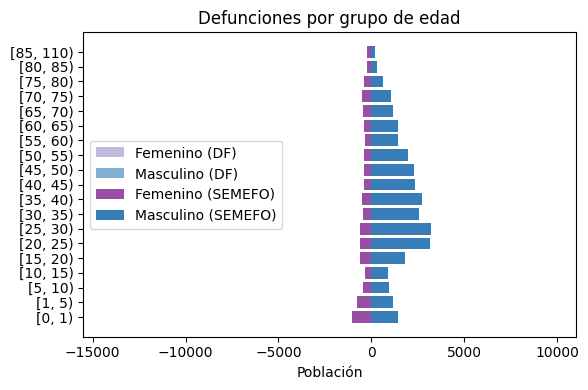

In [ ]:
dic_colors = {'Masculino (SEMEFO)':'#377eb8','Femenino (SEMEFO)':'#984ea3','S-D (SEMEFO)':'#999999',
              'Masculino (DF)':'#80b1d3','Femenino (DF)':'#bebada','S-D (DF)':'#d9d9d9'}

# Set position for each age group
y = range(len(edad_sexo)) 
# Plotting
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(y, [-val for val in data['Femenino']], color='#bebada', label='Femenino (DF)') # Plot female bars (negative)
ax.barh(y, data['Masculino'], color='#80b1d3', label='Masculino (DF)') # Plot male bars (positive)
ax.barh(y, [-val for val in edad_sexo['Femenino']], color='#984ea3', label='Femenino (SEMEFO)') # Plot female bars (negative)
ax.barh(y, edad_sexo['Masculino'], color='#377eb8', label='Masculino (SEMEFO)') # Plot male bars (positive)
# Y-axis label and formatting
plt.xlim( -15500, 11000 )
ax.set_yticks(y) # Set age groups as y-ticks (on horizontal axis)
ax.set_yticklabels(edad_sexo.index)
# X-axis label and formatting
ax.set_xlabel('Población')
ax.set_title('Defunciones por grupo de edad')
ax.legend(loc='center left')
# Plotting
plt.tight_layout()
#plt.savefig("imagenes/BO_PiramidePoblacional_DF+SEMEFO.svg")
plt.show()

## Fecha
'Fecha_transcrito', 
'Fecha_estandar', 
'Fecha_año', 
'Fecha_mes',
'Fecha_diasemana',

### Ingresos anuales y diarios

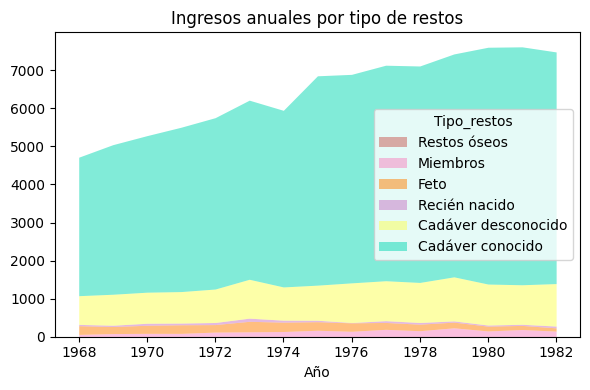

In [26]:
df_año_tipo = df.pivot_table(index='Fecha_año', columns='Tipo_restos', aggfunc='size')
df_año_tipo = df_año_tipo[df['Tipo_restos'].cat.categories].iloc[:, ::-1]
#display( df_año_tipo )

fig, ax = plt.subplots(figsize=(6, 4))
df_año_tipo.plot.area(ax=ax, color=dic_color, linewidth=0, alpha=0.5,)
ax.set_xlabel('Año')
ax.set_title('Ingresos anuales por tipo de restos')
ax.set_xticklabels([x.get_text().replace('.0','') for x in ax.get_xticklabels()]) # Remove negative sign from tick labels
plt.tight_layout()
#plt.savefig("imagenes/BO_TipoRestos+Sexo.svg")
plt.show()

**Ingresos diaros de toda la población**

En total, del 1968-01-01 al 1982-12-31 hay 5479 días
* Todos los días hubo ingresos
* Mediana de 17 ingresos diarios
* Min 2 ingresos, max 46 ingresos en un día

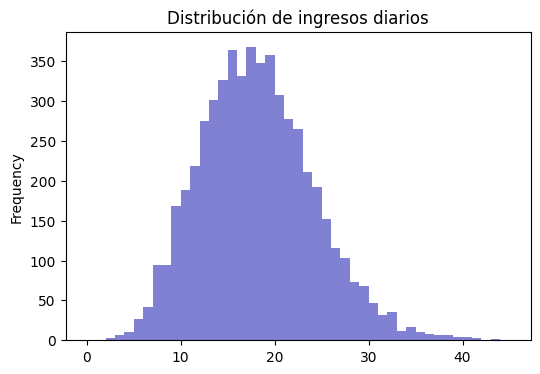

In [27]:
display()

fig, ax = plt.subplots(figsize=(6, 4))
df['Fecha_estandar'].value_counts().plot.hist(ax=ax, color=dic_color['Poblacion'], bins=range(46), alpha=0.5,
                      title='Distribución de ingresos diarios')
plt.show()

**Por tipo de restos**

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,count
count,5479.000000,4844.000000,548.000000,2077.000000,1525.000000,39.000000,5479.000000
mean,13.975908,2.980388,1.153285,1.366875,1.344262,1.205128,17.627122
std,5.212267,1.805487,0.446649,0.669469,0.695062,0.570295,6.060894
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000
25%,10.000000,2.000000,1.000000,1.000000,1.000000,1.000000,13.000000
50%,14.000000,3.000000,1.000000,1.000000,1.000000,1.000000,17.000000
75%,17.000000,4.000000,1.000000,2.000000,2.000000,1.000000,21.000000
max,36.000000,18.000000,5.000000,6.000000,9.000000,3.000000,46.000000


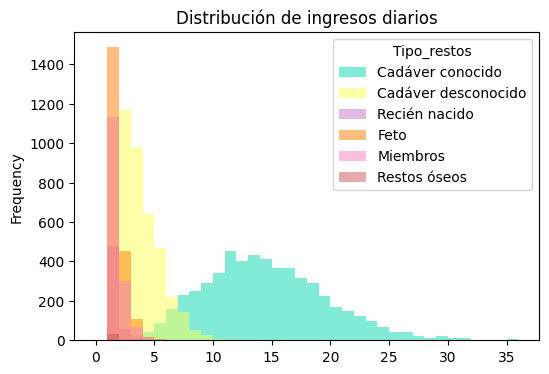

In [28]:
ing_diarios = df.pivot_table(index='Fecha_estandar', columns='Tipo_restos', aggfunc='size').sort_index().replace(0,nan)
display(pd.concat( [ing_diarios.describe(),df['Fecha_estandar'].value_counts().describe()], axis=1 ))

fig, ax = plt.subplots(figsize=(6, 4))
ing_diarios.plot.hist(ax=ax, color=dic_color, bins=range(37), alpha=0.5,
                      title='Distribución de ingresos diarios')

#plt.savefig("imagenes/BO_Distribucion_TipoRestos+IngresosDiarios.svg")
plt.show()

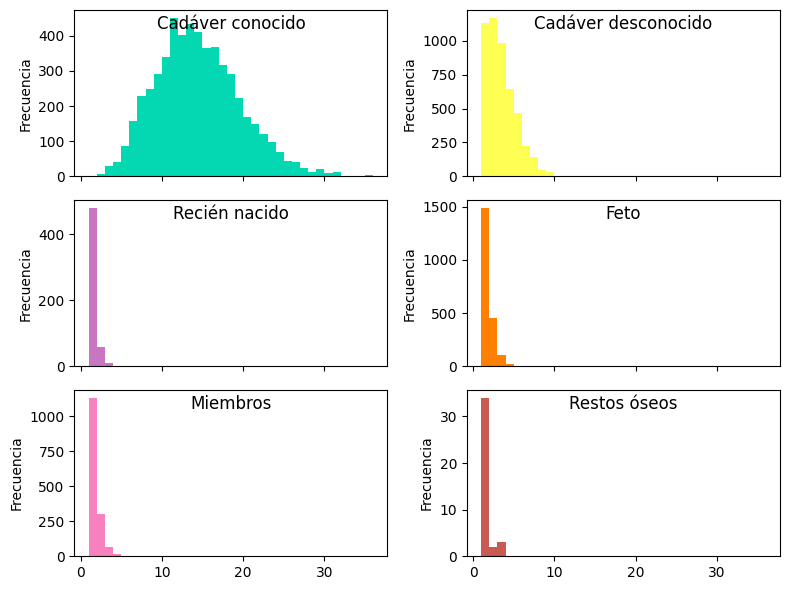

In [29]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 6), sharex=True)
axes = axes.flatten()

for ax,col in zip(axes,ing_diarios.columns):
    ing_diarios[col].plot.hist(ax=ax, color=dic_color[col], bins=range(1,37), ylabel='Frecuencia' )
    ax.set_title(col, y=1.0, pad=-14)
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

### Periodicidad entre años y semana



**Mediana de ingresos semanales**

In [30]:
ingresos_semanales = df.pivot_table(index='Fecha_semana', columns='Fecha_año', aggfunc='size').sort_index()
ingresos_semanales.median()

Fecha_año
1968.0     90.0
1969.0     94.0
1970.0     99.0
1971.0    102.0
1972.0    110.0
1973.0    117.0
1974.0    114.0
1975.0    132.0
1976.0    130.0
1977.0    134.0
1978.0    136.0
1979.0    142.0
1980.0    144.0
1981.0    146.0
1982.0    143.0
dtype: float64

* Incremento en ingresos en diciembre y primera de enero

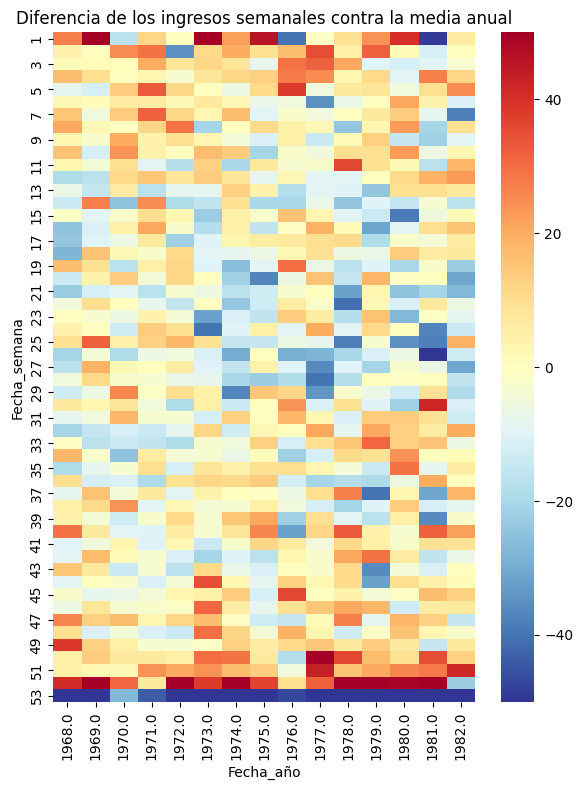

In [31]:
fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(ax=ax, data=ingresos_semanales-ingresos_semanales.median(), vmin=-50, vmax=50, cmap='RdYlBu_r', )
plt.title('Diferencia de los ingresos semanales contra la media anual')
plt.tight_layout()
plt.show()

In [32]:
ingresos_semanales.median()

Fecha_año
1968.0     90.0
1969.0     94.0
1970.0     99.0
1971.0    102.0
1972.0    110.0
1973.0    117.0
1974.0    114.0
1975.0    132.0
1976.0    130.0
1977.0    134.0
1978.0    136.0
1979.0    142.0
1980.0    144.0
1981.0    146.0
1982.0    143.0
dtype: float64

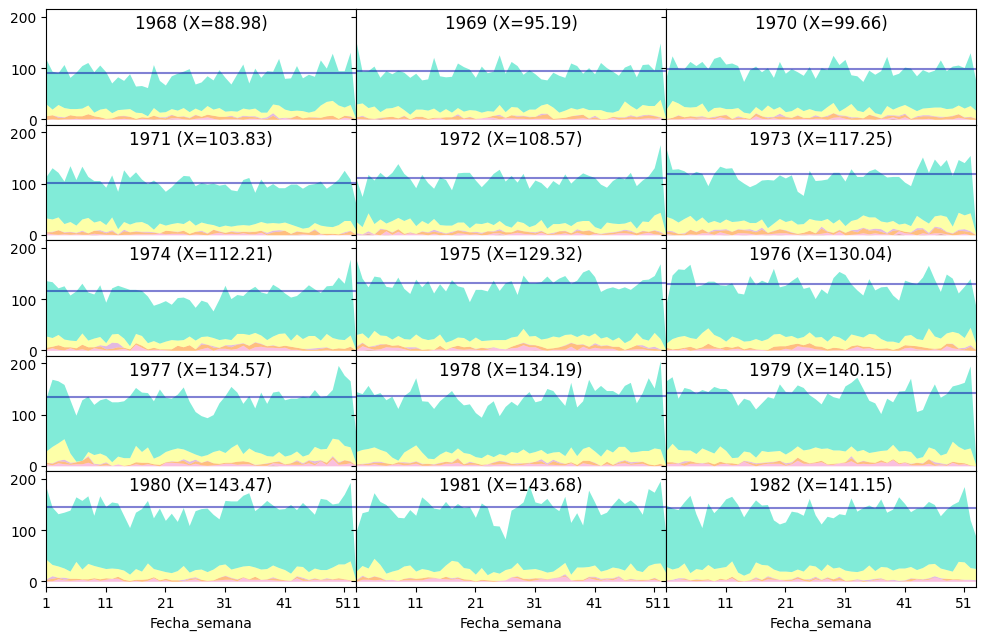

In [33]:
ncols = 3
fig, axes = plt.subplots(nrows=round(df['Fecha_año'].nunique()/ncols), ncols=ncols, 
                         figsize=(12,df['Fecha_año'].nunique()*1.5/ncols), 
                         sharex=True, sharey=True, )
for ax,año in zip(axes.flatten(),df['Fecha_año'].sort_values().dropna().unique()):
    data = df.loc[df['Fecha_año']==año,['Fecha_semana','Tipo_restos']]
    mediana_semanal = data.groupby('Fecha_semana', observed=True).size().median()
    data = data.pivot_table(index='Fecha_semana',columns='Tipo_restos',aggfunc='size').iloc[:, ::-1]
    data.plot.area(ax=ax, color=dic_color, linewidth=0, alpha=0.5)
    ax.axhline(y=mediana_semanal, color=dic_color['Poblacion'], alpha=0.5)
    ax.margins(x=0)
    ax.set_title(f"{int(año)} (X={data.sum(axis=1).mean().round(2)})", y=1.0, pad=-14)
    ax.get_legend().remove()
plt.subplots_adjust(wspace=0, hspace=0)
#plt.savefig("imagenes/BO_SemanaAño+TipoRestos.svg")
plt.show()

### Ingresos por dia de la semana

In [34]:
df['Fecha_diasemana'].value_counts()

Fecha_diasemana
Lunes        16578
Martes       15090
Miercoles    13615
Jueves       13132
Domingo      12731
Sábado       12727
Viernes      12706
Name: count, dtype: int64

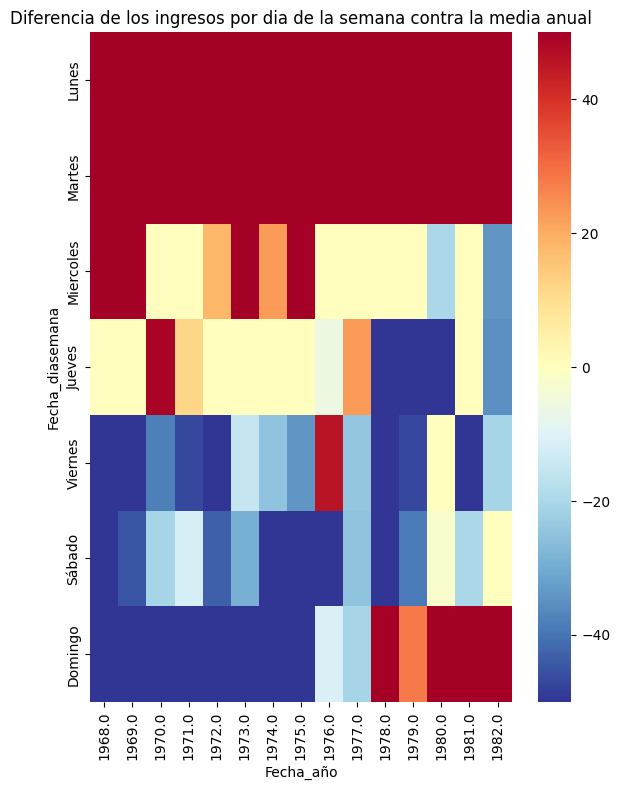

In [35]:
ingresos_diasem = df.pivot_table(index='Fecha_diasemana', columns='Fecha_año', aggfunc='size').sort_index()

fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(ax=ax, data=ingresos_diasem-ingresos_diasem.median(), vmin=-50, vmax=50, cmap='RdYlBu_r', )
plt.title('Diferencia de los ingresos por dia de la semana contra la media anual')
plt.tight_layout()
#plt.savefig("imagenes/BO_DiaSemana+Ingresos.svg")
plt.show()

### Ingresos fuera de año y patrón

* Sin fecha de ingreso
* Errores de conversión de fecha (29 de febrero por ejemplo)
* Ultimo mes del año anterior
* Primer mes del año posterior
* Casos especiales
    * En la bitacora de 1973 hay varios de 1974, consecutivos de la v a la x
    * Casos del futuro
    * Podría ser cuestión de transcripción
    
    

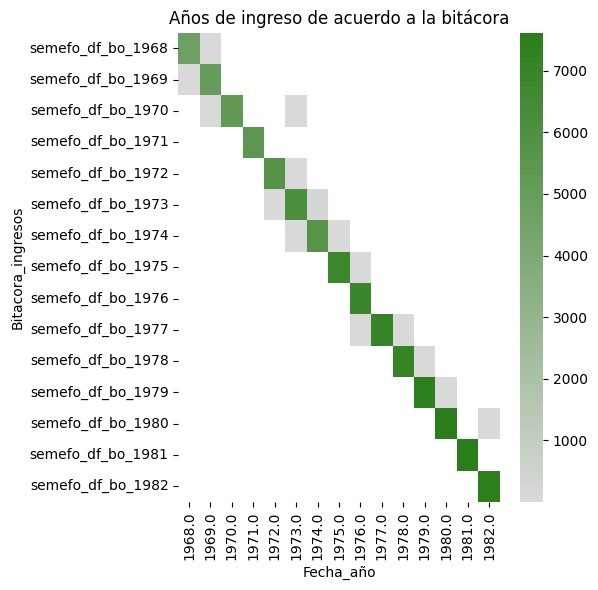

In [36]:
data = df.pivot_table(index='Bitacora_ingresos', columns='Fecha_año', aggfunc='size').replace(0,nan).sort_index()
fig, ax = plt.subplots(figsize=(6, 6))
sns.heatmap(ax=ax, data=data, cmap=gray_to_green, )
plt.title('Años de ingreso de acuerdo a la bitácora')
plt.tight_layout()
plt.show()

In [37]:
for bit in df['Bitacora_ingresos'].unique():
    print(bit)
    año_bit = int(bit.replace('semefo_df_bo_',''))
    display(bit, df[(df['Bitacora_ingresos']==bit) & (df['Fecha_año']!=año_bit) & (df['Fecha_transcrito']!='S-D')] )
    print('\n')
    

semefo_df_bo_1968


'semefo_df_bo_1968'

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1968_04658,S-D,valadez alanis francisco,valadez,alanis,francisco,1969-01-01,1969-01-01,1969.0,1.0,1,...,S-D,NaN,NaN,NaN,NaN,S-D,4875,semefo_df_bo_1968,121 reverso,se indica que fue entregado en 1969.
BO_1968_04659,S-D,vazquez contreras carlos,vazquez,contreras,carlos,1969-07-28,1969-07-28,1969.0,7.0,31,...,S-D,NaN,NaN,NaN,NaN,S-D,4815,semefo_df_bo_1968,121 reverso,se indica que fue entregado en 1969.




semefo_df_bo_1969


'semefo_df_bo_1969'

...

'semefo_df_bo_1981'

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1981_06369,S-D,desconocido,NaN,NaN,NaN,1981-02-31,NaT,NaN,NaN,NaN,...,36,HV,Hospital la Villa (Col Granjas Modernas),Gustavo A Madero,Hospital,154,646,semefo_df_bo_1981,115 reverso,marca de verificacion al final del nombre; pun...
BO_1981_06560,S-D,desconocido,NaN,NaN,NaN,31/04/1981,NaT,NaN,NaN,NaN,...,18,IZC-2,Coord Territorial 2 Iztacalco (Col Gabriel Ram...,Iztacalco,Judicial,841,1860,semefo_df_bo_1981,118 reverso,marca de verificacion al final del nombre. la ...
BO_1981_06561,S-D,desconocido,NaN,NaN,NaN,31/04/1981,NaT,NaN,NaN,NaN,...,18,IZC-2,Coord Territorial 2 Iztacalco (Col Gabriel Ram...,Iztacalco,Judicial,842,1861,semefo_df_bo_1981,118 reverso,marca de verificacion al final del nombre. la ...
BO_1981_06562,S-D,desconocido,NaN,NaN,NaN,31/04/1981,NaT,NaN,NaN,NaN,...,15,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,Judicial,455,1865,semefo_df_bo_1981,118 reverso,marca de verificacion al final del nombre. la ...
BO_1981_06577,S-D,desconocido,NaN,NaN,NaN,31/04/1981,NaT,NaN,NaN,NaN,...,36,HV,Hospital la Villa (Col Granjas Modernas),Gustavo A Madero,Hospital,498,1926,semefo_df_bo_1981,119,punto rojo en expediente_semefo. la bitacora o...




semefo_df_bo_1982


'semefo_df_bo_1982'

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,


## Nombre
'Nombre_completo_transcrito',
'Primer_apellido', 
'Segundo_apellido', 
'Nombres_propios',

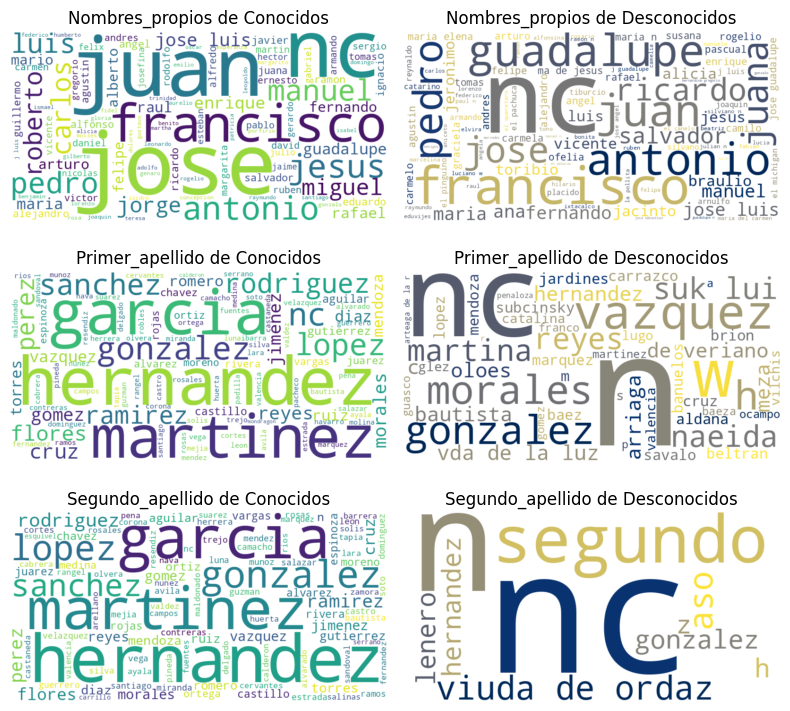

In [38]:
cols = ['Nombres_propios','Primer_apellido', 'Segundo_apellido', ]
fig, axes = plt.subplots(nrows=len(cols), ncols=2, figsize=(8, 2.5*len(cols)), sharex=True)

for i,col in enumerate(cols): 
    freq_cono = df.loc[df['Conocido_desconocido']=='Conocido',col] \
                  .apply(simplify_string, remove_special=True) \
                  .value_counts().head(100).to_dict()
    wordcloud = WordCloud(width=800, height=400,
                          relative_scaling=0.5, 
                          background_color='white') \
                          .generate_from_frequencies(freq_cono)
    # Display the word cloud
    axes[i,0].imshow(wordcloud, interpolation='bilinear')
    axes[i,0].axis('off')
    axes[i,0].set_title(f"{col} de Conocidos")
    
    freq_des = df.loc[df['Conocido_desconocido']=='Desconocido',col] \
                  .apply(simplify_string, remove_special=True) \
                  .value_counts().head(100).to_dict()
    wordcloud = WordCloud(width=800, height=400,
                          relative_scaling=0.5, 
                          colormap='cividis', background_color='white') \
                          .generate_from_frequencies(freq_des)
    # Display the word cloud
    axes[i,1].imshow(wordcloud, interpolation='bilinear')
    axes[i,1].axis('off')
    axes[i,1].set_title(f"{col} de Desconocidos")
plt.tight_layout()
#plt.savefig("imagenes/BO_Wordcloud_Nombre.svg")
plt.show()

### Datos faltantes en nombre

Nos centraremos en las variables que permiten la identificación de un individuo: 'Primer_apellido', 'Segundo_apellido', 'Nombres_propios'.

In [39]:
col_identi = ['Primer_apellido', 'Segundo_apellido', 'Nombres_propios']
thr_short = 2

Es importante decir que existen nombres de dos caracteres, los cuales se usan a veces para indicar que no hay información: 'nc', 'n', '', 'sd', 'rc' o que solo se conoce la inicial en 4883/5145 (94.90%) de los casos.

In [40]:
data = [df[col].str.replace('[^a-zA-Z]', '', regex=True) for col in col_identi]
data = [col[col.str.len()<=thr_short] for col in data]
data
data = pd.concat(data, ignore_index=True)
print(f'Total nombres de {thr_short} caracteres o menos: {data.shape[0]}')
print(f'Ejemplos: {data.unique()}')
data.value_counts().head()

Total nombres de 2 caracteres o menos: 5145
Ejemplos: ['nc' 'h' 'n' 'd' 'w' 'l' 'm' 'de' 'c' 'uh' 'su' 'p' 'r' 'mm' 'o' 'cu' 'f'
 'ke' 'mc' 'e' 'yu' 's' 'pe' 'jo' 'j' 'a' '' 'ku' 'g' 'ma' 'la' 'b' 'sd'
 't' 'le' 'vi' 'z' 'vc' 'v' 'go' 'nj' 'hy' 'ch' 'fe' 'jm' 'me' 'vm' 'vv'
 'ml' 'fv' 'sn' 'wu' 'rn' 'dh' 'mi']


nc    4255
n      625
de      48
w       42
ma      25
Name: count, dtype: int64

Veamos los datos faltantes:

In [41]:
data = pd.DataFrame()
for col in col_identi:
    col_clean = df[col].str.replace('[^a-zA-Z]', '', regex=True)
    col_nan = col_clean.isna()
    col_short = col_clean.str.len()<=thr_short
    data[f'{col}_desc'] = col_nan | col_short
display(data.sum())
display(data.sum()/df.shape[0])

display(data.sum(axis=1).value_counts().sort_index())
display(data.sum(axis=1).value_counts(normalize=True).sort_index())

Primer_apellido_desc     20131
Segundo_apellido_desc    22771
Nombres_propios_desc     20347
dtype: int64

Primer_apellido_desc     0.207911
Segundo_apellido_desc    0.235177
Nombres_propios_desc     0.210142
dtype: float64

0    73382
1     3369
2      342
3    19732
Name: count, dtype: int64

0    0.757883
1    0.034795
2    0.003532
3    0.203790
Name: proportion, dtype: float64